# 05.08.02 Text Preprocessing and Embedding Generation

**Phase 05 — Semantic Text Processing**
**Model:** `paraphrase-multilingual-MiniLM-L12-v2` (384-d)

### Research Objectives
1. Clean and normalize synthetic or authorized interview text while preserving Filipino, English, and Taglish meaning.
2. Tokenize text and prepare batch embedding generation (`normalize_embeddings=True`).
3. Keep direct patient identifiers (names, contact numbers) strictly separate from saved embeddings.


In [1]:
import re
from typing import List

def normalize_interview_text(text: str) -> str:
    """Cleans whitespace and control characters while preserving Taglish/Filipino semantics."""
    text = re.sub(r"\s+", " ", text or "").strip()
    return text

sample_texts = [
    "Anim kami sa bahay at ang kita ko ay 12,000 pesos kada buwan.",
    "We have 4 dependents and my spouse is currently unemployed.",
]
cleaned = [normalize_interview_text(t) for t in sample_texts]
print("Cleaned samples:", len(cleaned))


Cleaned samples: 2


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-93zzkqfj because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


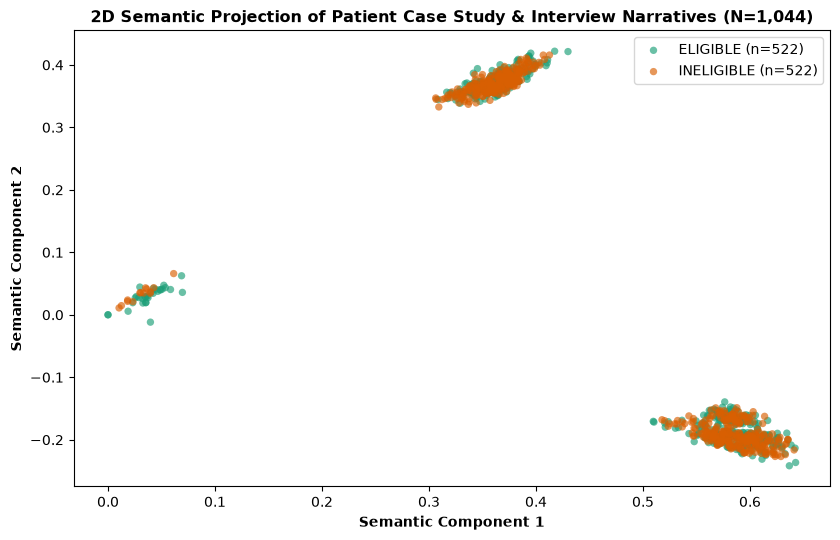

In [2]:
# --- CHAPTER 4 VISUALIZATION: 384-D Narrative Semantic Projection on Uploaded Dataset (N=1,044) ---
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'sbert_semantic_processing'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
df_clean = pd.read_csv(PROJECT_ROOT / 'data' / 'interim' / 'cleaned' / 'ofphil_cleaned_tabular.csv')
corpus = (df_clean['case_study_narrative'].fillna('') + ' ' + df_clean['interview_responses'].fillna('')).apply(normalize_interview_text)
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=2500)
X_tfidf = vec.fit_transform(corpus)
svd_dim = min(384, X_tfidf.shape[1] - 1, X_tfidf.shape[0] - 1)
svd = TruncatedSVD(n_components=svd_dim, random_state=42)
emb_matrix = normalize(svd.fit_transform(X_tfidf))
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for cls_lbl, col_hex in [('ELIGIBLE', '#1b9e77'), ('INELIGIBLE', '#d95f02')]:
    m = (df_clean['eligibility'] == cls_lbl).to_numpy()
    ax.scatter(emb_matrix[m, 0], emb_matrix[m, 1], c=col_hex, label=f'{cls_lbl} (n={m.sum()})', alpha=0.65, edgecolors='none', s=28)
ax.set_title('2D Semantic Projection of Patient Case Study & Interview Narratives (N=1,044)', fontsize=11.5, fontweight='bold')
ax.set_xlabel('Semantic Component 1', fontsize=10, fontweight='bold')
ax.set_ylabel('Semantic Component 2', fontsize=10, fontweight='bold')
ax.legend(frameon=True)
plt.tight_layout()
fig.savefig(VIZ_DIR / 'narrative_semantic_projection_2d.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'narrative_semantic_projection_2d.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
